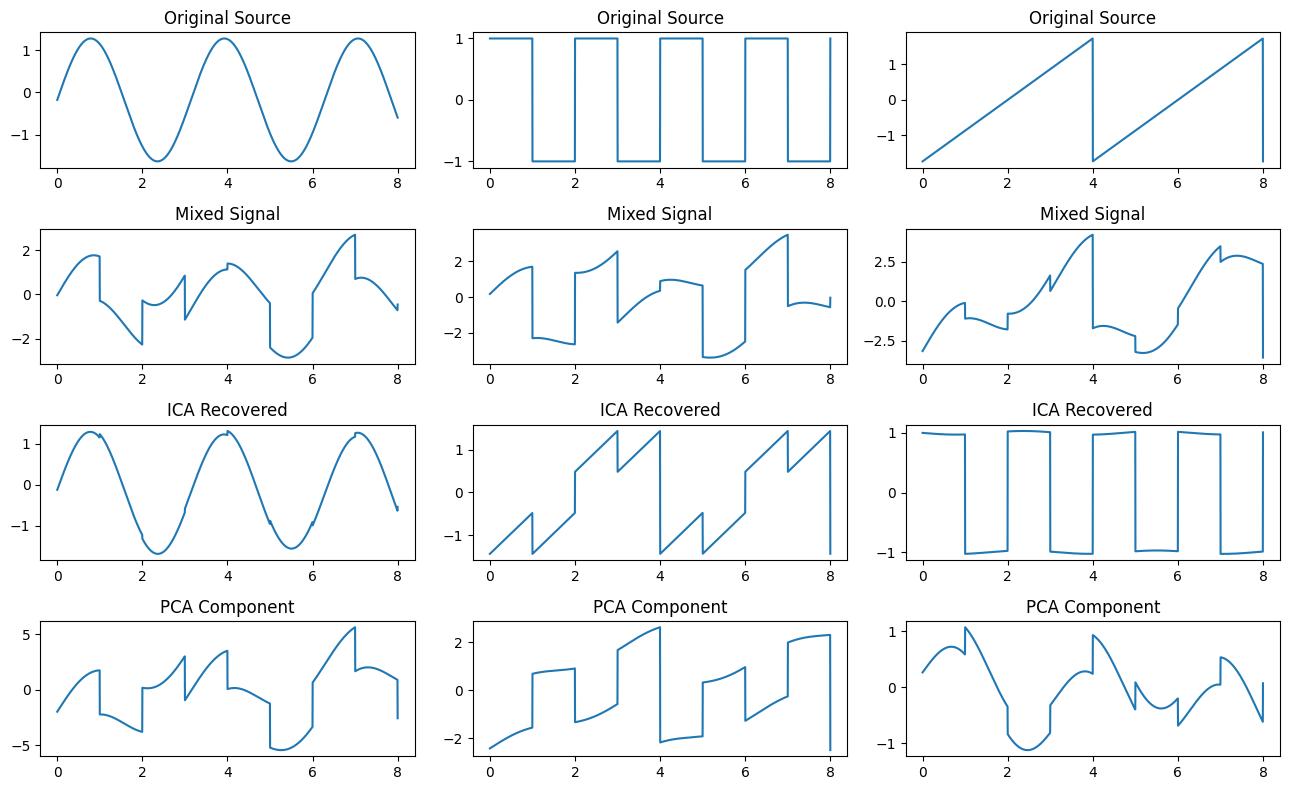

Absolute Source Correlations:
[[9.98568130e-01 4.97311027e-02 1.97105693e-02]
 [2.03452770e-02 1.49871519e-04 9.99793002e-01]
 [7.77359935e-03 9.01452502e-01 4.32808222e-01]]


In [12]:

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from sklearn.decomposition import FastICA, PCA

t = np.linspace(0, 8, 2000)

S = np.c_[
    np.sin(2*t),
    signal.square(2*np.pi*0.5*t),
    signal.sawtooth(2*np.pi*0.25*t)
]

S = (S-S.mean(0))/S.std(0)

A = np.array([
    [1, 1, 0.5],
    [0.5, 2, 1],
    [1, 0.5, 2]
])

X = S @ A.T

ica = FastICA(
    n_components=3,
    random_state=42,
    max_iter=1000,
    whiten="unit-variance"
)

S_ica = ica.fit_transform(X)
S_pca = PCA(n_components=3).fit_transform(X)

fig, ax = plt.subplots(4, 3, figsize=(13, 8))

for j in range(3):
    ax[0,j].plot(t, S[:,j])
    ax[0,j].set_title("Original Source")

    ax[1,j].plot(t, X[:,j])
    ax[1,j].set_title("Mixed Signal")

    ax[2,j].plot(t, S_ica[:,j])
    ax[2,j].set_title("ICA Recovered")

    ax[3,j].plot(t, S_pca[:,j])
    ax[3,j].set_title("PCA Component")

plt.tight_layout()
plt.show()

print("Absolute Source Correlations:")
print(np.abs(np.corrcoef(S.T, S_ica.T)[:3, 3:]))
